# Weather Report: 86 years of climate in five European cities

**Question:** how has the climate of Milan, Palermo, Berlin, London and Madrid
changed from 1940 to 2025?

**Data:** daily maximum, minimum and mean temperature and precipitation from the
[Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api),
ERA5 reanalysis (Copernicus Climate Change Service).

**Method:** all the code lives in the `weather_report` package. This notebook only
imports its functions and tells the story of the analysis.

In [32]:
import sys
from pathlib import Path

# Make the project package importable from the notebooks/ folder
sys.path.insert(0, str(Path.cwd().parent))

In [33]:
from weather_report import analysis, plots, storage
from weather_report.config import CITIES, RECENT_PERIOD, REFERENCE_PERIOD
from weather_report.processing import build_tables

## 1. Loading the data

`build_tables` runs the whole pipeline: it reads the raw CSV cache
(downloading only the missing cities), cleans the data and builds
the daily, monthly and yearly tables.

In [34]:
tables = build_tables()
daily = tables["daily"]
monthly = tables["monthly"]
annual = tables["annual"]

Milan: loaded from milan_1940-01-01_2025-12-31.csv
Palermo: loaded from palermo_1940-01-01_2025-12-31.csv
Berlin: loaded from berlin_1940-01-01_2025-12-31.csv
London: loaded from london_1940-01-01_2025-12-31.csv
Madrid: loaded from madrid_1940-01-01_2025-12-31.csv
daily: saved to daily.csv
monthly: saved to monthly.csv
annual: saved to annual.csv


In [35]:
daily.shape, monthly.shape, annual.shape

((157060, 5), (5160, 5), (430, 5))

In [36]:
daily.head()

,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,city
time,,,,,
1940-01-01,2.3,-5.5,-1.8,NaN,Milan
1940-01-02,1.4,-5.3,-2.1,0.0,Milan
1940-01-03,-1.7,-6.0,-4.2,0.0,Milan
1940-01-04,3.2,-2.9,0.1,1.5,Milan
1940-01-05,5.8,-1.0,2.4,0.3,Milan


In [37]:
daily.isna().sum()

temperature_2m_max     0
temperature_2m_min     0
temperature_2m_mean    0
precipitation_sum      5
city                   0
dtype: int64

Five cities × 31,412 days = 157,060 rows in long format, with one `city` column.
Only a handful of values are missing: `mean` and `sum` simply skip them.

## 2. The climate of the five cities

Descriptive statistics of the daily mean temperature over the whole
period 1940-2025: mean, standard deviation, minimum and maximum.

In [38]:
summary = analysis.city_summary(daily)
summary

,mean,std,min,max
city,,,,
Berlin,9.27,7.87,-20.6,29.8
London,10.52,5.48,-8.7,29.1
Madrid,14.30,7.76,-8.8,32.8
Milan,13.10,8.06,-12.1,32.2
Palermo,18.60,6.32,2.0,36.9


In [39]:
path = storage.save_table(summary, "temperature_summary")

Palermo is the warmest city (mean 18.6 °C) and Berlin the coldest (9.27 °C).
The standard deviation measures how much daily temperature varies over the
year: it is largest in the continental climates (Milan, Berlin, Madrid) and smallest where
the sea mitigates temperatures (Palermo, London). The five cities really cover five
different climates.

## 3. Temperature anomalies

Each city has its own climate, so to compare them we use the **anomaly**:
the difference between each year's mean temperature and the city's
climate normal, the 1961-1990 average (WMO standard reference period).

In [40]:
anomalies = analysis.annual_anomalies(annual)
anomalies.tail()

,city,anomaly
time,,
2021-01-01,Palermo,1.79
2022-01-01,Palermo,2.30
2023-01-01,Palermo,1.97
2024-01-01,Palermo,2.21
2025-01-01,Palermo,1.76


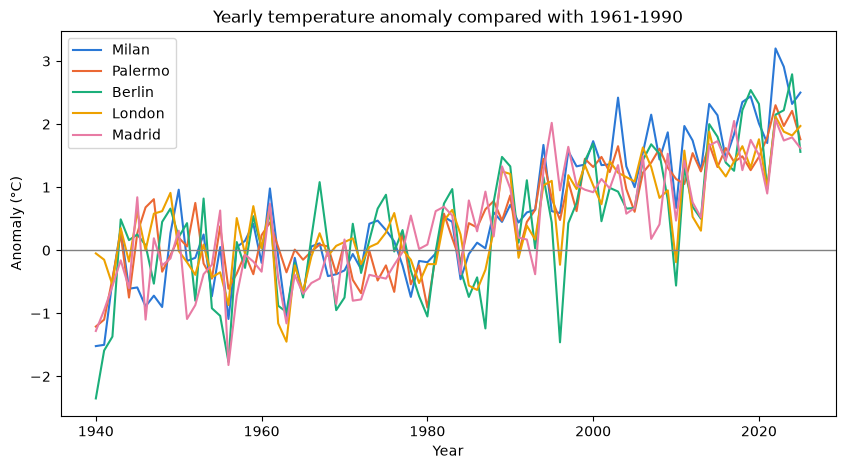

In [41]:
fig = plots.plot_anomalies(anomalies)
path = storage.save_figure(fig, "anomalies")

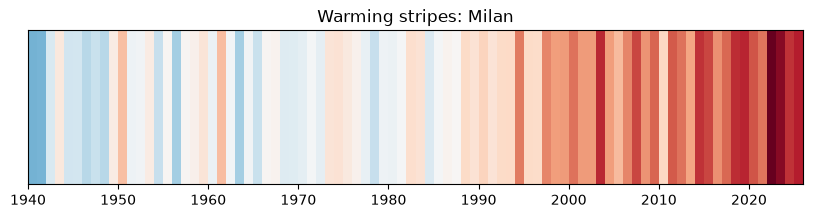

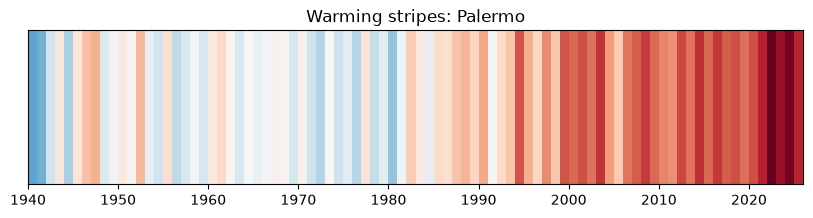

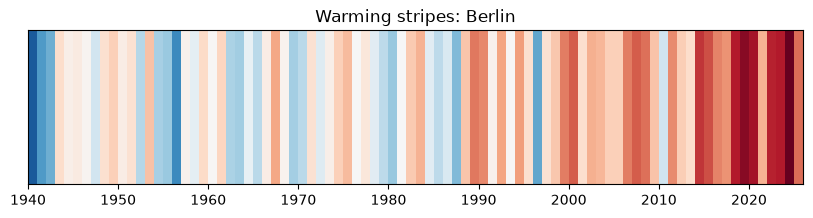

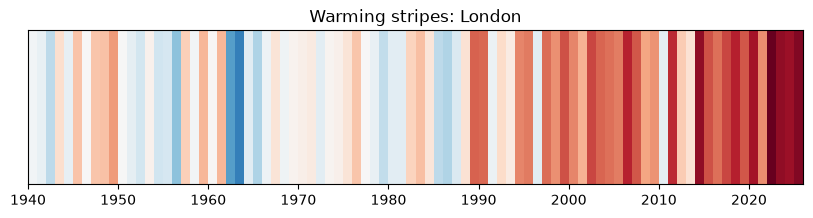

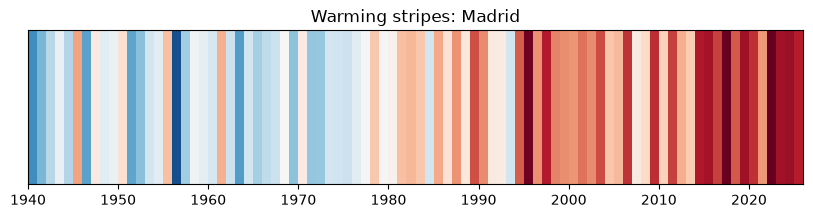

In [42]:
for city in CITIES:
    fig = plots.plot_warming_stripes(anomalies, city.name)
    path = storage.save_figure(fig, f"stripes_{city.slug}")

Until the 1980s the anomalies oscillate around zero, after that all the 
cities have started to warm up faster than before.
Since then all five cities have been warming, and in the last decades almost every year is
warmer than the 1961-1990 normal. 
The hot summers of 2003 and 2022 stand out. The warming stripes show the same 
story at a glance: blue years in the first half of the period, red years in the last decades.